
# Homework 2 — Regression & Classification with scikit-learn

**Course:** Artificial Intelligence  
**Names:**  Ali Emre Kaya
**Deliverables:** Jupyter Notebook  
**This version intentionally omits most implementations. Your task is to complete all TODOs.**

**Work individually or in pairs.** Include **full names and student numbers** at the top of this notebook and in your report.

**Objective:** Train/test **regression** and **binary classification** models using scikit-learn; evaluate with appropriate metrics; compare models and summarize findings.


## 0) Setup — run this first

In [25]:

# Do not change names
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, RocCurveDisplay
)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_diabetes, load_breast_cancer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment ready.")

Environment ready.



## 1) Data (fixed datasets)

Use only the following **built-in** datasets:
- **Regression:** Diabetes dataset (`load_diabetes`)  
- **Classification:** Breast cancer dataset (`load_breast_cancer`)


In [26]:

# Load fixed datasets (no external data)
reg_data = load_diabetes(as_frame=True)
X_reg, y_reg = reg_data.data, reg_data.target

cls_data = load_breast_cancer(as_frame=True)
X_cls, y_cls = cls_data.data, pd.Series(cls_data.target, name="target")

print("Regression data shape:", X_reg.shape)
print("Classification data shape:", X_cls.shape)

Regression data shape: (442, 10)
Classification data shape: (569, 30)



## 2) Train/Test Split (TODO)

Create 80/20 splits. Use **stratification** for the classification target.


In [27]:

# TODO: regression split (80/20)
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# TODO: classification split (80/20, stratified) # stratified-> Train ve test setindeki sınıf oranlarını aynı tutar.
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_cls, y_cls, test_size=0.2, stratify=y_cls, random_state=42)



## 3) Regression — Baseline & Tuned (TODO)

- Train a **baseline linear model** using a scaling + linear regression pipeline.  
- Train a **regularized model** with cross-validated hyperparameters.  
- Report **MAE, MSE, R²** on the **test set** for both models.


In [28]:

# TODO: baseline regression model
# steps:
#   - build a pipeline with scaling + a linear regressor
#   - fit on training data
#   - predict on test data
#   - compute MAE, MSE, R2

reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

reg_pipeline.fit(Xr_train, yr_train)

yr_pred = reg_pipeline.predict(Xr_test)

mae = mean_absolute_error(yr_test, yr_pred)
mse = mean_squared_error(yr_test, yr_pred)
r2  = r2_score(yr_test, yr_pred)

print("MAE : ", mae)
print("MSE : ", mse)
print("R2  : ", r2)

MAE :  42.79409467959994
MSE :  2900.1936284934827
R2  :  0.45260276297191926


In [29]:

# TODO: tuned regression model
# steps:
#   - build a pipeline with scaling + a regularized regressor
#   - choose a small hyperparameter grid
#   - use cross-validation for tuning
#   - evaluate the best model on test data (MAE, MSE, R2)

tuned_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0,]
}

grid = GridSearchCV(
    tuned_pipeline,
    param_grid
)

grid.fit(Xr_train, yr_train)

print("Best parameters:", grid.best_params_)
print("Best CV score (MSE):", grid.best_score_)

# evaluation
best_model = grid.best_estimator_

y_pred_tuned = best_model.predict(Xr_test)

mae = mean_absolute_error(yr_test, y_pred_tuned)
mse = mean_squared_error(yr_test, y_pred_tuned)
r2  = r2_score(yr_test, y_pred_tuned)

print(f"MAE : {mae:.4f}")
print(f"MSE : {mse:.4f}")
print(f"R2  : {r2:.4f}")


Best parameters: {'model__alpha': 10.0}
Best CV score (MSE): 0.4539374157959351
MAE : 42.8568
MSE : 2875.7787
R2  : 0.4572



## 4) Classification — Two Models (TODO)

- Train a **linear classifier** using a scaling + logistic classifier pipeline.  
- Train a **tree-based classifier** with a small hyperparameter search.  
- Report **Accuracy, Precision, Recall, F1, AUC**, print the **confusion matrix**, and plot **ROC** (one curve per model).


=== Linear Classifier Results (LogisticRegression + Scaling) ===
Accuracy : 0.9824561403508771
Precision: 0.9861111111111112
Recall   : 0.9861111111111112
F1-score : 0.9861111111111112
AUC      : 0.9953703703703703

Confusion matrix:
[[41  1]
 [ 1 71]]


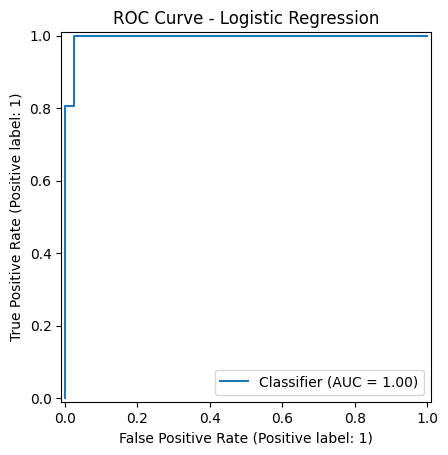

In [30]:

# TODO: linear classifier
# steps:
#   - build a pipeline with scaling + a linear classifier
#   - fit on training data
#   - predict class labels and probabilities on test data
#   - compute metrics (acc, prec, rec, f1, auc)
#   - print confusion matrix
#   - plot ROC curve

clf_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

clf_pipeline.fit(Xc_train, yc_train)

y_pred = clf_pipeline.predict(Xc_test)
y_proba = clf_pipeline.predict_proba(Xc_test)[:, 1]  # positive class probability


acc = accuracy_score(yc_test, y_pred)
prec = precision_score(yc_test, y_pred)
rec = recall_score(yc_test, y_pred)
f1 = f1_score(yc_test, y_pred)
auc = roc_auc_score(yc_test, y_proba)

print("=== Linear Classifier Results (LogisticRegression + Scaling) ===")
print(f"Accuracy : {acc}")
print(f"Precision: {prec}")
print(f"Recall   : {rec}")
print(f"F1-score : {f1}")
print(f"AUC      : {auc}")
print()

cm = confusion_matrix(yc_test, y_pred)
print("Confusion matrix:")
print(cm)


RocCurveDisplay.from_predictions(yc_test, y_proba)
plt.title("ROC Curve - Logistic Regression")
plt.show()


Best params (tree): {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best CV AUC      : 0.9604395604395606

=== Tree-based Classifier Results (RandomForest) ===
Accuracy : 0.956140350877193
Precision: 0.958904109589041
Recall   : 0.9722222222222222
F1-score : 0.9655172413793104
AUC      : 0.9930555555555556

Confusion matrix (tree):
[[39  3]
 [ 2 70]]


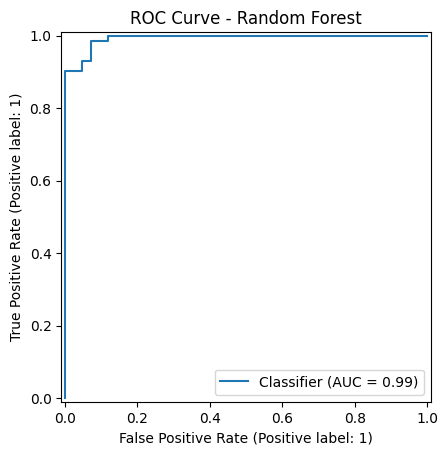

In [31]:

# TODO: tree-based classifier
# steps:
#   - instantiate a tree-based classifier
#   - define a small hyperparameter grid
#   - use stratified CV for tuning
#   - evaluate best model on test data (metrics + ROC)

tree_clf = RandomForestClassifier(
    random_state=RANDOM_STATE
)

param_grid_tree = {
    "n_estimators": [50, 100, 200, 400],
    "max_depth": [None, 5, 10, 25, 100],
    "min_samples_split": [2, 5, 12]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_tree = GridSearchCV(
    estimator=tree_clf,
    param_grid=param_grid_tree,
    n_jobs=-1
)

grid_tree.fit(Xc_train, yc_train)

print("Best params (tree):", grid_tree.best_params_)
print("Best CV AUC      :", grid_tree.best_score_)



best_tree = grid_tree.best_estimator_

y_pred_tree = best_tree.predict(Xc_test)
y_proba_tree = best_tree.predict_proba(Xc_test)[:, 1]

acc = accuracy_score(yc_test, y_pred_tree)
prec = precision_score(yc_test, y_pred_tree)
rec = recall_score(yc_test, y_pred_tree)
f1 = f1_score(yc_test, y_pred_tree)
auc = roc_auc_score(yc_test, y_proba_tree)

print("\n=== Tree-based Classifier Results (RandomForest) ===")
print(f"Accuracy : {acc}")
print(f"Precision: {prec}")
print(f"Recall   : {rec}")
print(f"F1-score : {f1}")
print(f"AUC      : {auc}")

cm_tree = confusion_matrix(yc_test, y_pred_tree)
print("\nConfusion matrix (tree):")
print(cm_tree)

# ROC curve
RocCurveDisplay.from_predictions(yc_test, y_proba_tree)
plt.title("ROC Curve - Random Forest")
plt.show()



## 5) Comparison Tables (TODO)

Create two tables summarizing **test metrics**:
- Regression: (Model, MAE, MSE, R²)  
- Classification: (Model, Accuracy, Precision, Recall, F1, AUC)


In [32]:
# TODO: assemble results tables for regression and classification
# Example:
# reg_results = pd.DataFrame([...], columns=["Model","MAE","MSE","R2"])
# cls_results = pd.DataFrame([...], columns=["Model","Acc","Prec","Rec","F1","AUC"])
# display(reg_results); display(cls_results)



baseline_mae = mean_absolute_error(yr_test, yr_pred)
baseline_mse = mean_squared_error(yr_test, yr_pred)
baseline_r2 = r2_score(yr_test, yr_pred)

tuned_mae = mean_absolute_error(yr_test, y_pred_tuned)
tuned_mse = mean_squared_error(yr_test, y_pred_tuned)
tuned_r2 = r2_score(yr_test, y_pred_tuned)

reg_results = pd.DataFrame([
    ["Linear Regression", baseline_mae, baseline_mse, baseline_r2],
    ["Ridge Regression", tuned_mae, tuned_mse, tuned_r2]
], columns=["Model", "MAE", "MSE", "R2"])

print("=== REGRESSION RESULTS ===")
display(reg_results)




log_acc = accuracy_score(yc_test, y_pred)
log_prec = precision_score(yc_test, y_pred)
log_rec = recall_score(yc_test, y_pred)
log_f1 = f1_score(yc_test, y_pred)
log_auc = roc_auc_score(yc_test, y_proba)

rf_acc = accuracy_score(yc_test, y_pred_tree)
rf_prec = precision_score(yc_test, y_pred_tree)
rf_rec = recall_score(yc_test, y_pred_tree)
rf_f1 = f1_score(yc_test, y_pred_tree)
rf_auc = roc_auc_score(yc_test, y_proba_tree)

cls_results = pd.DataFrame([
    ["Logistic Regression", log_acc, log_prec, log_rec, log_f1, log_auc],
    ["Random Forest", rf_acc, rf_prec, rf_rec, rf_f1, rf_auc]
], columns=["Model", "Acc", "Prec", "Rec", "F1", "AUC"])

print("\n=== CLASSIFICATION RESULTS ===")
display(cls_results)

=== REGRESSION RESULTS ===


,Model,MAE,MSE,R2
0,Linear Regression,42.794095,2900.193628,0.452603
1,Ridge Regression,42.856825,2875.778718,0.457211



=== CLASSIFICATION RESULTS ===


,Model,Acc,Prec,Rec,F1,AUC
0,Logistic Regression,0.982456,0.986111,0.986111,0.986111,0.995370
1,Random Forest,0.956140,0.958904,0.972222,0.965517,0.993056



## 6) Report

Report your work in the Report cell below by summarizing:
- Metric results and observations  
- Why certain models performed better  
- Effect of scaling and hyperparameter tuning  
- One limitation and one improvement idea


### Report 
report link 
<a href="report.pdf">report.pdf</a>


## Submission Checklist
- Notebook runs top-to-bottom without errors  
- All TODOs completed  
- Comparison tables included  
- `report.pdf` attached (1–2 pages)  
- Both names and student numbers are visible
